# Script pour la production de différents plot

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Lecture des fichiers

In [10]:
df_KO_WT = pd.read_csv("results_KO_WT.csv", sep=",")
df_KO_induced = pd.read_csv("results_KO_induced.csv", sep=",")
df_WT_induced = pd.read_csv("results_WT_induced.csv", sep=",")
df_KO_WT_induced = pd.read_csv("results_KO_WT_induced.csv", sep=",")

Renommage des la colonne des noms des gènes

In [11]:
df_KO_WT=df_KO_WT.rename(columns={"Geneid" : "gene_ID"})
df_KO_induced=df_KO_induced.rename(columns={"Geneid" : "gene_ID"})
df_KO_WT_induced=df_KO_WT_induced.rename(columns={"Geneid" : "gene_ID"})
df_WT_induced=df_WT_induced.rename(columns={"Geneid" : "gene_ID"})

In [12]:
df_KO_WT

,gene_ID,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
0,ENSG00000310526,219.713955,0.307920,0.142171,2.165835,0.030324,0.118961
1,ENSG00000243485,1.872687,0.217570,0.723234,0.300829,0.763545,NaN
2,ENSG00000308361,0.217830,-0.474298,2.608873,-0.181802,0.855738,NaN
3,ENSG00000241860,16.567196,0.022844,0.330535,0.069112,0.944900,0.974120
4,ENSG00000233750,24.751765,-0.395688,0.219779,-1.800386,0.071800,0.215428
...,...,...,...,...,...,...,...
46766,ENSG00000229236,14.288245,0.630410,0.261861,2.407425,0.016065,0.075394
46767,ENSG00000277438,0.226295,1.432984,3.079870,0.465274,0.641735,NaN
46768,ENSG00000198692,2356.485383,-0.331556,0.141252,-2.347259,0.018912,0.085012
46769,ENSG00000280969,0.931795,0.277806,1.228028,0.226221,0.821029,NaN


## Chargement Biomart

On va chargé le fichier Biomart pour pouvoir avoir le nom des gènes et leur identifiant.

In [13]:
biomart = pd.read_csv("biomart.csv")
biomart=biomart.rename(columns={"Gene stable ID": "gene_ID"})
biomart_clean=biomart[["gene_ID", "Gene name"]]
biomart_clean=biomart_clean.drop_duplicates(subset="gene_ID")
biomart_clean

,gene_ID,Gene name
0,ENSG00000210049,MT-TF
1,ENSG00000211459,MT-RNR1
2,ENSG00000210077,MT-TV
3,ENSG00000210082,MT-RNR2
4,ENSG00000209082,MT-TL1
...,...,...
533467,ENSG00000168710,AHCYL1
533480,ENSG00000081692,JMJD4
533499,ENSG00000157873,TNFRSF14
533530,ENSG00000132676,DAP3


Fusion des noms des gènes avec l'identifiant dans les fichiers de résultats

In [14]:
df_KO_WT_results = pd.merge(df_KO_WT, biomart_clean, how='inner', on="gene_ID")
df_KO_induced_results = pd.merge(df_KO_induced, biomart_clean, how='inner', on="gene_ID")
df_KO_WT_induced_results = pd.merge(df_KO_WT_induced, biomart_clean, how='inner', on="gene_ID")
df_WT_induced_results = pd.merge(df_WT_induced, biomart_clean, how='inner', on="gene_ID")


In [15]:
df_KO_WT_induced_results

,gene_ID,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,Gene name
0,ENSG00000310526,219.713955,-0.169284,0.151148,-1.119992,0.262717,0.636960,WASH7P
1,ENSG00000243485,1.872687,-0.773010,0.856159,-0.902882,0.366588,NaN,MIR1302-2HG
2,ENSG00000308361,0.217830,-0.163422,2.786397,-0.058650,0.953231,NaN,NaN
3,ENSG00000241860,16.567196,0.096739,0.362621,0.266779,0.789640,0.944937,NaN
4,ENSG00000233750,24.751765,0.992548,0.273050,3.635037,0.000278,0.005944,CICP27
...,...,...,...,...,...,...,...,...
46766,ENSG00000229236,14.288245,0.610169,0.270172,2.258449,0.023918,0.172494,TTTY10
46767,ENSG00000277438,0.226295,-0.080822,3.448491,-0.023437,0.981302,NaN,KDM5DP1
46768,ENSG00000198692,2356.485383,0.036162,0.149223,0.242334,0.808521,0.951101,EIF1AY
46769,ENSG00000280969,0.931795,0.175362,1.378814,0.127183,0.898795,NaN,RPS4Y2


## Volcano plot

### KO vs WT

In [ ]:
#seuil
logfc_thr=1
padj_thr=0.05

#Suppression des données nuls
df=df_KO_WT_results.dropna(subset=["padj", "log2FoldChange"]).copy()

#Prendre les valeurs de padj supérieur à 0 et calculer le log10padj
df = df[df["padj"]>0]
df['log10padj']=-np.log10(df["padj"])

#Construire les variables up, down et non significatives
up= (df["padj"]<padj_thr) & (df["log2FoldChange"]> logfc_thr)
down = (df["padj"]<padj_thr)&(df["log2FoldChange"]< -logfc_thr)
ns=~(up|down)

print(up.sum())
print(down.sum())

plt.figure(figsize=(6,5), dpi=300)

#Construire du plot
plt.scatter(
    df[ns]["log2FoldChange"],
    df[ns]["log10padj"],
    c="lightgrey",
    s=10,
    alpha=0.6,
    label="Not significant"
)

plt.scatter(
    df[up]["log2FoldChange"],
    df[up]["log10padj"],
    c="firebrick",
    s=15,
    alpha=0.8,
    label="Up_Regulated"
)

plt.scatter(
    df[down]["log2FoldChange"],
    df[down]["log10padj"],
    c="royalblue",
    s=15,
    alpha=0.8,
    label="Down_Regulated"
)

#seuils à tracer
plt.axvline(logfc_thr, linestyle="--", color="black", linewidth=1)
plt.axvline(-logfc_thr, linestyle="--", color="black", linewidth=1)
plt.axhline(-np.log10(padj_thr), linestyle="--", color="black", linewidth=1)

#Annotation des 10 gènes les plus différentiellement exprimés
top_up = (
    df[up].sort_values("log2FoldChange", ascending=False).head(10)
)
top_down=(
    df[down].sort_values("log2FoldChange").head(10)
)

top=pd.concat([top_up, top_down])

from adjustText import adjust_text

texts=[]

for _, r in top.iterrows():
    texts.append(
        plt.text(
            r["log2FoldChange"],
            r["log10padj"],
            r["Gene name"],
            fontsize=7
        )
    )

adjust_text(
    texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
)

#Mise en page
plt.xlabel("log2 Fold Change")
plt.ylabel("log10 adjusted p-value")
plt.title("Volcano plot KO vs WT - Expression différentiels")
plt.legend(frameon=False)

plt.tight_layout()
plt.savefig("Volcano_plot_KO_vs_WT.pdf", format="pdf")
plt.show()

### KOind vs WTind

In [ ]:
#seuil
logfc_thr=1
padj_thr=00.5

#Suppression des données nuls
df = df_KO_WT_induced_results.dropna(subset=["padj", "log2FoldChange"]).copy()

#Prendre les valeurs de padj supérieur à 0 et calculer le log10padj
df=df[df["padj"]>0]
df["log10padj"] = -np.log10(df["padj"])

#Construire les variables up, down et non significatives
up = (df["padj"] < padj_thr)&(df["log2FoldChange"]>logfc_thr)
down = (df["padj"]< padj_thr)&(df["log2FoldChange"]<-logfc_thr)
ns =~(up|down)

plt.figure(figsize=(6,5), dpi=300)

#Construire du plot
plt.scatter(
    df[ns]["log2FoldChange"],
    df[ns]["log10padj"],
    s=10,
    c="lightgrey",
    alpha=0.6,
    label="Not significant"
)

plt.scatter(
    df[up]["log2FoldChange"],
    df[up]["log10padj"],
    s=10,
    c="firebrick",
    alpha=0.8,
    label="Up_Regulated"
)

plt.scatter(
    df[down]["log2FoldChange"],
    df[down]["log10padj"],
    s=10,
    c="royalblue",
    alpha=0.8,
    label="Down_Regulated"
)

#Seuils à tracer

plt.axvline(logfc_thr, linestyle='--', color='black', linewidth=1)
plt.axvline(-logfc_thr, linestyle='--', color='black', linewidth=1)
plt.axhline(-np.log10(padj_thr), linestyle="--", color="black", linewidth=1)

#Annotation des 10 gènes les plus différentiellement exprimés

top_up=(
    df[up].sort_values("log2FoldChange", ascending=False).head(10)
)

top_down=(
    df[down].sort_values("log2FoldChange").head(10)
)

top = pd.concat([top_up, top_down])

from adjustText import adjust_text

texts=[]

for _, r in top.iterrows():
    texts.append(
        plt.text(
        r["log2FoldChange"],
        r["log10padj"],
        r["Gene name"]
    )
)

adjust_text(
    texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
)


#Mise en page
plt.xlabel("log2 Fold Change")
plt.ylabel("log10 adjusted p-value")
plt.title("Volcano plot KOind vs WTind - Expression différentiels")
plt.legend(frameon=False)

plt.tight_layout()
plt.savefig("Volcano_plot_KOind_vs_WTind.pdf", format="pdf")
plt.show()


### KOind vs KO

In [ ]:
#seuil
logfc_thr=1
padj_thr=00.5

#Suppression des données nuls
df = df_KO_induced_results.dropna(subset=["padj", "log2FoldChange"]).copy()

#Prendre les valeurs de padj supérieur à 0 et calculer le log10padj
df=df[df["padj"]>0]
df["log10padj"] = -np.log10(df["padj"])

#Construire les variables up, down et non significatives
up = (df["padj"] < padj_thr)&(df["log2FoldChange"]>logfc_thr)
down = (df["padj"]< padj_thr)&(df["log2FoldChange"]<-logfc_thr)
ns =~(up|down)

plt.figure(figsize=(6,5), dpi=300)

#Construire du plot
plt.scatter(
    df[ns]["log2FoldChange"],
    df[ns]["log10padj"],
    s=10,
    c="lightgrey",
    alpha=0.6,
    label="Not significant"
)

plt.scatter(
    df[up]["log2FoldChange"],
    df[up]["log10padj"],
    s=10,
    c="firebrick",
    alpha=0.8,
    label="Up_Regulated"
)

plt.scatter(
    df[down]["log2FoldChange"],
    df[down]["log10padj"],
    s=10,
    c="royalblue",
    alpha=0.8,
    label="Down_Regulated"
)

#Seuils à tracer

plt.axvline(logfc_thr, linestyle='--', color='black', linewidth=1)
plt.axvline(-logfc_thr, linestyle='--', color='black', linewidth=1)
plt.axhline(-np.log10(padj_thr), linestyle="--", color="black", linewidth=1)

#Annotation des 10 gènes les plus différentiellement exprimés

top_up=(
    df[up].sort_values("log2FoldChange", ascending=False).head(10)
)

top_down=(
    df[down].sort_values("log2FoldChange").head(10)
)

top = pd.concat([top_up, top_down])

from adjustText import adjust_text

texts=[]

for _, r in top.iterrows():
    texts.append(
        plt.text(
        r["log2FoldChange"],
        r["log10padj"],
        r["Gene name"]
    )
)

adjust_text(
    texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
)


#Mise en page
plt.xlabel("log2 Fold Change")
plt.ylabel("log10 adjusted p-value")
plt.title("Volcano plot KOind vs KO - Expression différentiels")
plt.legend(frameon=False)

plt.tight_layout()
plt.savefig("Volcano_plot_KOind_vs_KO.pdf", format="pdf")
plt.show()


### WTind vs WT

In [ ]:
#seuil
logfc_thr=1
padj_thr=00.5

#Suppression des données nuls
df = df_WT_induced_results.dropna(subset=["padj", "log2FoldChange"]).copy()

#Prendre les valeurs de padj supérieur à 0 et calculer le log10padj
df=df[df["padj"]>0]
df["log10padj"] = -np.log10(df["padj"])

#Construire les variables up, down et non significatives
up = (df["padj"] < padj_thr)&(df["log2FoldChange"]>logfc_thr)
down = (df["padj"]< padj_thr)&(df["log2FoldChange"]<-logfc_thr)
ns =~(up|down)

plt.figure(figsize=(6,5), dpi=300)

#Construire du plot
plt.scatter(
    df[ns]["log2FoldChange"],
    df[ns]["log10padj"],
    s=10,
    c="lightgrey",
    alpha=0.6,
    label="Not significant"
)

plt.scatter(
    df[up]["log2FoldChange"],
    df[up]["log10padj"],
    s=10,
    c="firebrick",
    alpha=0.8,
    label="Up_Regulated"
)

plt.scatter(
    df[down]["log2FoldChange"],
    df[down]["log10padj"],
    s=10,
    c="royalblue",
    alpha=0.8,
    label="Down_Regulated"
)

#Seuils à tracer

plt.axvline(logfc_thr, linestyle='--', color='black', linewidth=1)
plt.axvline(-logfc_thr, linestyle='--', color='black', linewidth=1)
plt.axhline(-np.log10(padj_thr), linestyle="--", color="black", linewidth=1)

#Annotation des 10 gènes les plus différentiellement exprimés

top_up=(
    df[up].sort_values("log2FoldChange", ascending=False).head(10)
)

top_down=(
    df[down].sort_values("log2FoldChange").head(10)
)

top = pd.concat([top_up, top_down])

from adjustText import adjust_text

texts=[]

for _, r in top.iterrows():
    texts.append(
        plt.text(
        r["log2FoldChange"],
        r["log10padj"],
        r["Gene name"]
    )
)

adjust_text(
    texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
)


#Mise en page
plt.xlabel("log2 Fold Change")
plt.ylabel("log10 adjusted p-value")
plt.title("Volcano plot WTind vs WT - Expression différentiels")
plt.legend(frameon=False)

plt.tight_layout()
plt.savefig("Volcano_plot_WTind_vs_WT.pdf", format="pdf")
plt.show()


## Recalcule pour faire la pca

On utilise pydeseq

In [43]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

In [44]:
metadata_df = pd.read_csv("metadata.csv", sep=',')
counts=pd.read_csv("final_counts.csv", sep=',')

On fixe les index pour que cela marche

In [47]:
metadata_df = metadata_df.set_index("Unnamed: 0")

In [48]:
counts = counts.set_index("Unnamed: 0")

On calcule les statistiques par rapport à nos fichier

In [49]:
inference = DefaultInference(n_cpus=8)
dds = DeseqDataSet(
    counts=counts,
    metadata=metadata_df,
    design="~Condition",
    refit_cooks=True,
    inference=inference,
)

In [50]:
dds.deseq2()

Fitting size factors...
... done in 0.09 seconds.



Using None as control genes, passed at DeseqDataSet initialization


/home/rademe/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/rademe/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/rademe/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/rademe/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (
/

On calcule le log des comptes normalisé, on en fait un tableau et on fait le plot.

In [56]:
log_normalized_counts = np.log1p(dds.layers["normed_counts"])
log_normalized_counts_df = pd.DataFrame(log_normalized_counts.T, index=dds.var_names, columns=dds.obs_names)


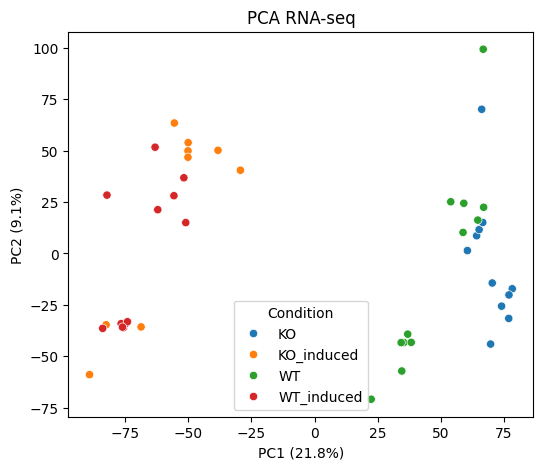

In [57]:
from sklearn.decomposition import PCA

X=log_normalized_counts_df.T

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.figure(figsize=(6,5))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=metadata_df["Condition"]
)
var_explained=pca.explained_variance_ratio_ *100

plt.xlabel(f"PC1 ({var_explained[0]:.1f}%)")
plt.ylabel(f"PC2 ({var_explained[1]:.1f}%)")
plt.title("PCA RNA-seq")
plt.savefig("PCA.pdf", format="pdf")
plt.show()

In [36]:
from matplotlib import colormaps
list(colormaps)


['magma',
 'inferno',
 'plasma',
 'viridis',
 'cividis',
 'twilight',
 'twilight_shifted',
 'turbo',
 'Blues',
 'BrBG',
 'BuGn',
 'BuPu',
 'CMRmap',
 'GnBu',
 'Greens',
 'Greys',
 'OrRd',
 'Oranges',
 'PRGn',
 'PiYG',
 'PuBu',
 'PuBuGn',
 'PuOr',
 'PuRd',
 'Purples',
 'RdBu',
 'RdGy',
 'RdPu',
 'RdYlBu',
 'RdYlGn',
 'Reds',
 'Spectral',
 'Wistia',
 'YlGn',
 'YlGnBu',
 'YlOrBr',
 'YlOrRd',
 'afmhot',
 'autumn',
 'binary',
 'bone',
 'brg',
 'bwr',
 'cool',
 'coolwarm',
 'copper',
 'cubehelix',
 'flag',
 'gist_earth',
 'gist_gray',
 'gist_heat',
 'gist_ncar',
 'gist_rainbow',
 'gist_stern',
 'gist_yarg',
 'gnuplot',
 'gnuplot2',
 'gray',
 'hot',
 'hsv',
 'jet',
 'nipy_spectral',
 'ocean',
 'pink',
 'prism',
 'rainbow',
 'seismic',
 'spring',
 'summer',
 'terrain',
 'winter',
 'Accent',
 'Dark2',
 'Paired',
 'Pastel1',
 'Pastel2',
 'Set1',
 'Set2',
 'Set3',
 'tab10',
 'tab20',
 'tab20b',
 'tab20c',
 'grey',
 'gist_grey',
 'gist_yerg',
 'Grays',
 'magma_r',
 'inferno_r',
 'plasma_r',
 'viri

## MA-plot

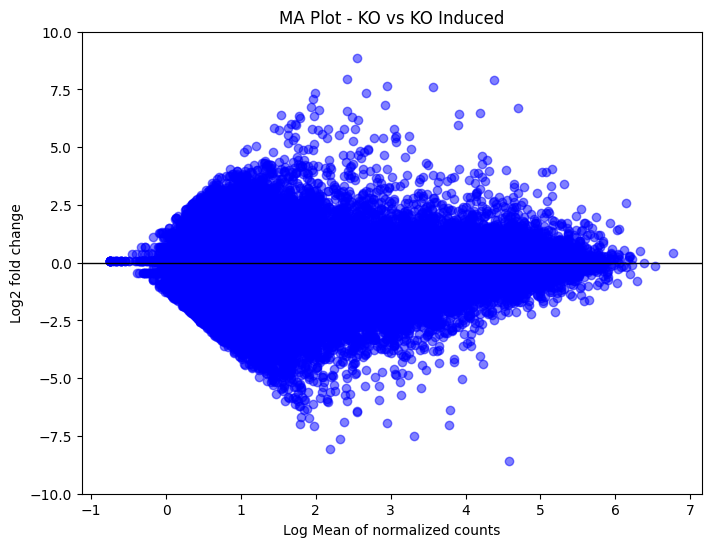

In [35]:
plt.figure(figsize=(8, 6))
plt.scatter((np.log10(df_KO_induced_results['baseMean'])+1), df_KO_induced_results['log2FoldChange'], alpha=0.5, color='blue')
plt.title('MA Plot - KO vs KO Induced')
plt.xlabel('Log Mean of normalized counts')
plt.ylabel('Log2 fold change')
plt.ylim(-10, 10)  # Limites de l'axe des Y
plt.axhline(0, color='black',linewidth=1)  # Ligne horizontale à y=0
plt.savefig("MA_plot_KO_induced.pdf", format="pdf")
plt.show()

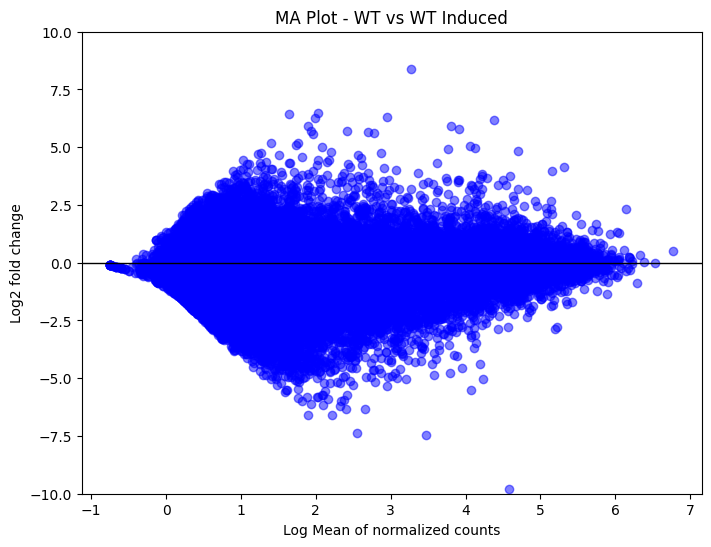

In [36]:
#Créer le graphique MA
plt.figure(figsize=(8, 6))
plt.scatter((np.log10(df_WT_induced_results['baseMean'])+1), df_WT_induced_results['log2FoldChange'], alpha=0.5, color='blue')
plt.title('MA Plot - WT vs WT Induced')
plt.xlabel('Log Mean of normalized counts')
plt.ylabel('Log2 fold change')
plt.ylim(-10, 10)  # Limites de l'axe des Y
plt.axhline(0, color='black',linewidth=1)  # Ligne horizontale à y=0
plt.savefig("MA_plot_WT_induced.pdf", format="pdf")
plt.show()

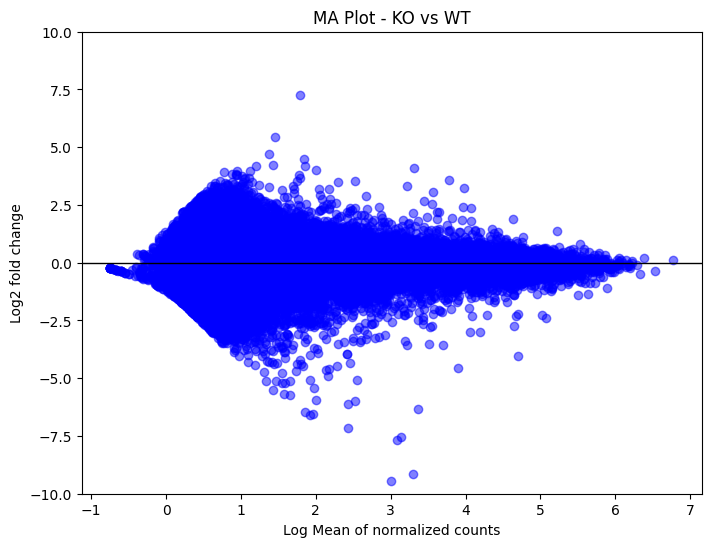

In [37]:
plt.figure(figsize=(8, 6))
plt.scatter((np.log10(df_KO_WT_results['baseMean'])+1), df_KO_WT_results['log2FoldChange'], alpha=0.5, color='blue')
plt.title('MA Plot - KO vs WT')
plt.xlabel('Log Mean of normalized counts')
plt.ylabel('Log2 fold change')
plt.ylim(-10, 10)  # Limites de l'axe des Y
plt.axhline(0, color='black',linewidth=1)  # Ligne horizontale à y=0
plt.savefig("MA_plot_KO_WT.pdf", format="pdf")
plt.show()

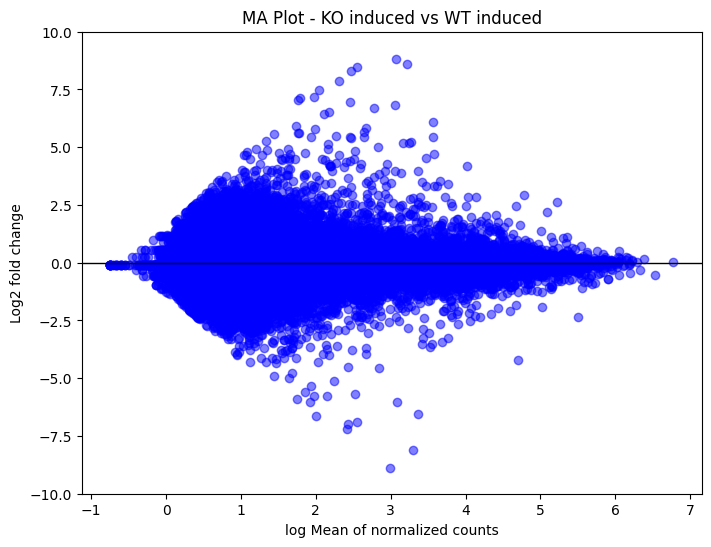

In [38]:
plt.figure(figsize=(8, 6))
plt.scatter((np.log10(df_KO_WT_induced_results['baseMean'])+1), df_KO_WT_induced_results['log2FoldChange'], alpha=0.5, color='blue')
plt.title('MA Plot - KO induced vs WT induced')
plt.xlabel('log Mean of normalized counts')
plt.ylabel('Log2 fold change')
plt.ylim(-10, 10)  # Limites de l'axe des Y
plt.axhline(0, color='black',linewidth=1)  # Ligne horizontale à y=0
plt.savefig("MA_plot_KO_WT_induced.pdf", format="pdf")
plt.show()

## Histogramme

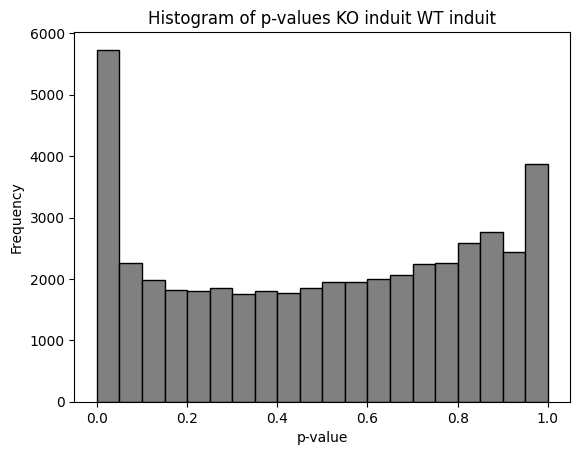

In [39]:
#Il faut juste remplacer le df_KO_WT_induced par les autre tableau
plt.hist(df_KO_WT_induced_results['pvalue'], bins=20, color='grey', edgecolor='black')
plt.title('Histogram of p-values KO induit WT induit')
plt.xlabel('p-value')
plt.ylabel('Frequency')
plt.savefig("Histogram_KO_WT_induced.pdf", format="pdf")
plt.show()

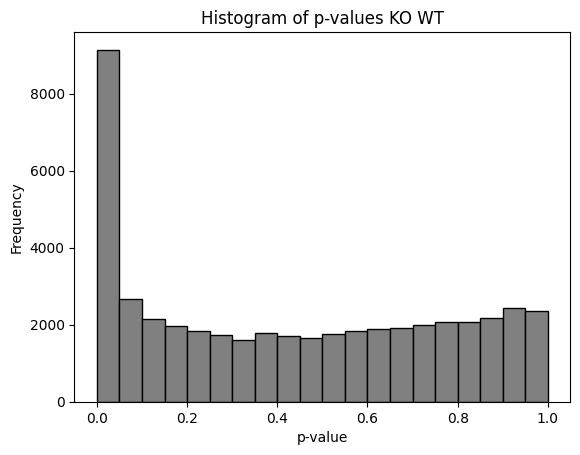

In [40]:
plt.hist(df_KO_WT_results['pvalue'], bins=20, color='Grey', edgecolor="black")
plt.title('Histogram of p-values KO WT')
plt.xlabel('p-value')
plt.ylabel('Frequency')
plt.savefig("Histogram_KO_WT.pdf", format="pdf")

plt.show()

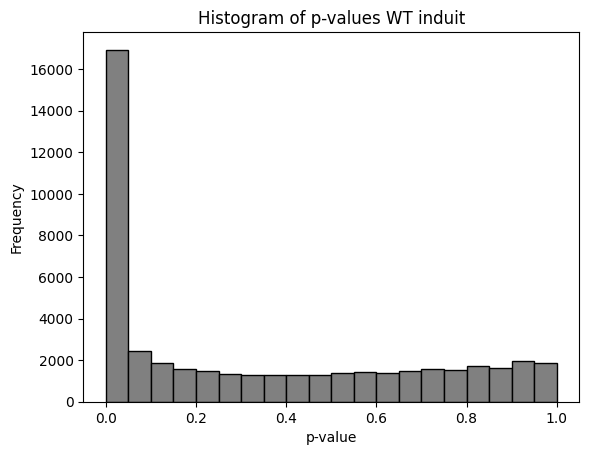

In [41]:
plt.hist(df_WT_induced_results['pvalue'], bins=20, color='grey', edgecolor="black")
plt.title('Histogram of p-values WT induit')
plt.xlabel('p-value')
plt.ylabel('Frequency')
plt.savefig("Histogram_WT_induced.pdf", format="pdf")
plt.show()

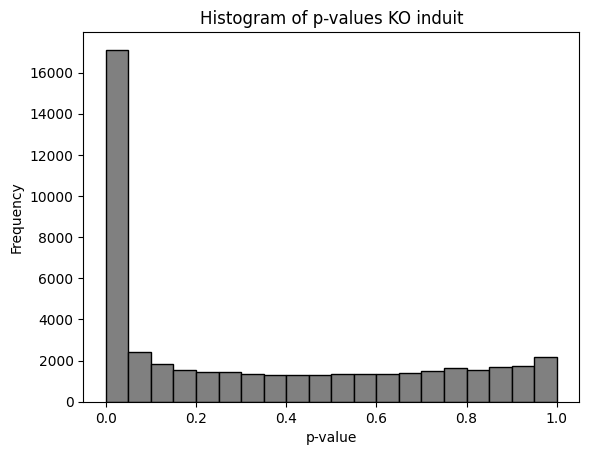

In [42]:
plt.hist(df_KO_induced_results['pvalue'], bins=20, color='Grey',edgecolor="black")
plt.title('Histogram of p-values KO induit')
plt.xlabel('p-value')
plt.ylabel('Frequency')
plt.savefig("Histogram_KO_induced.pdf", format="pdf")
plt.show()

## Dispersion plot

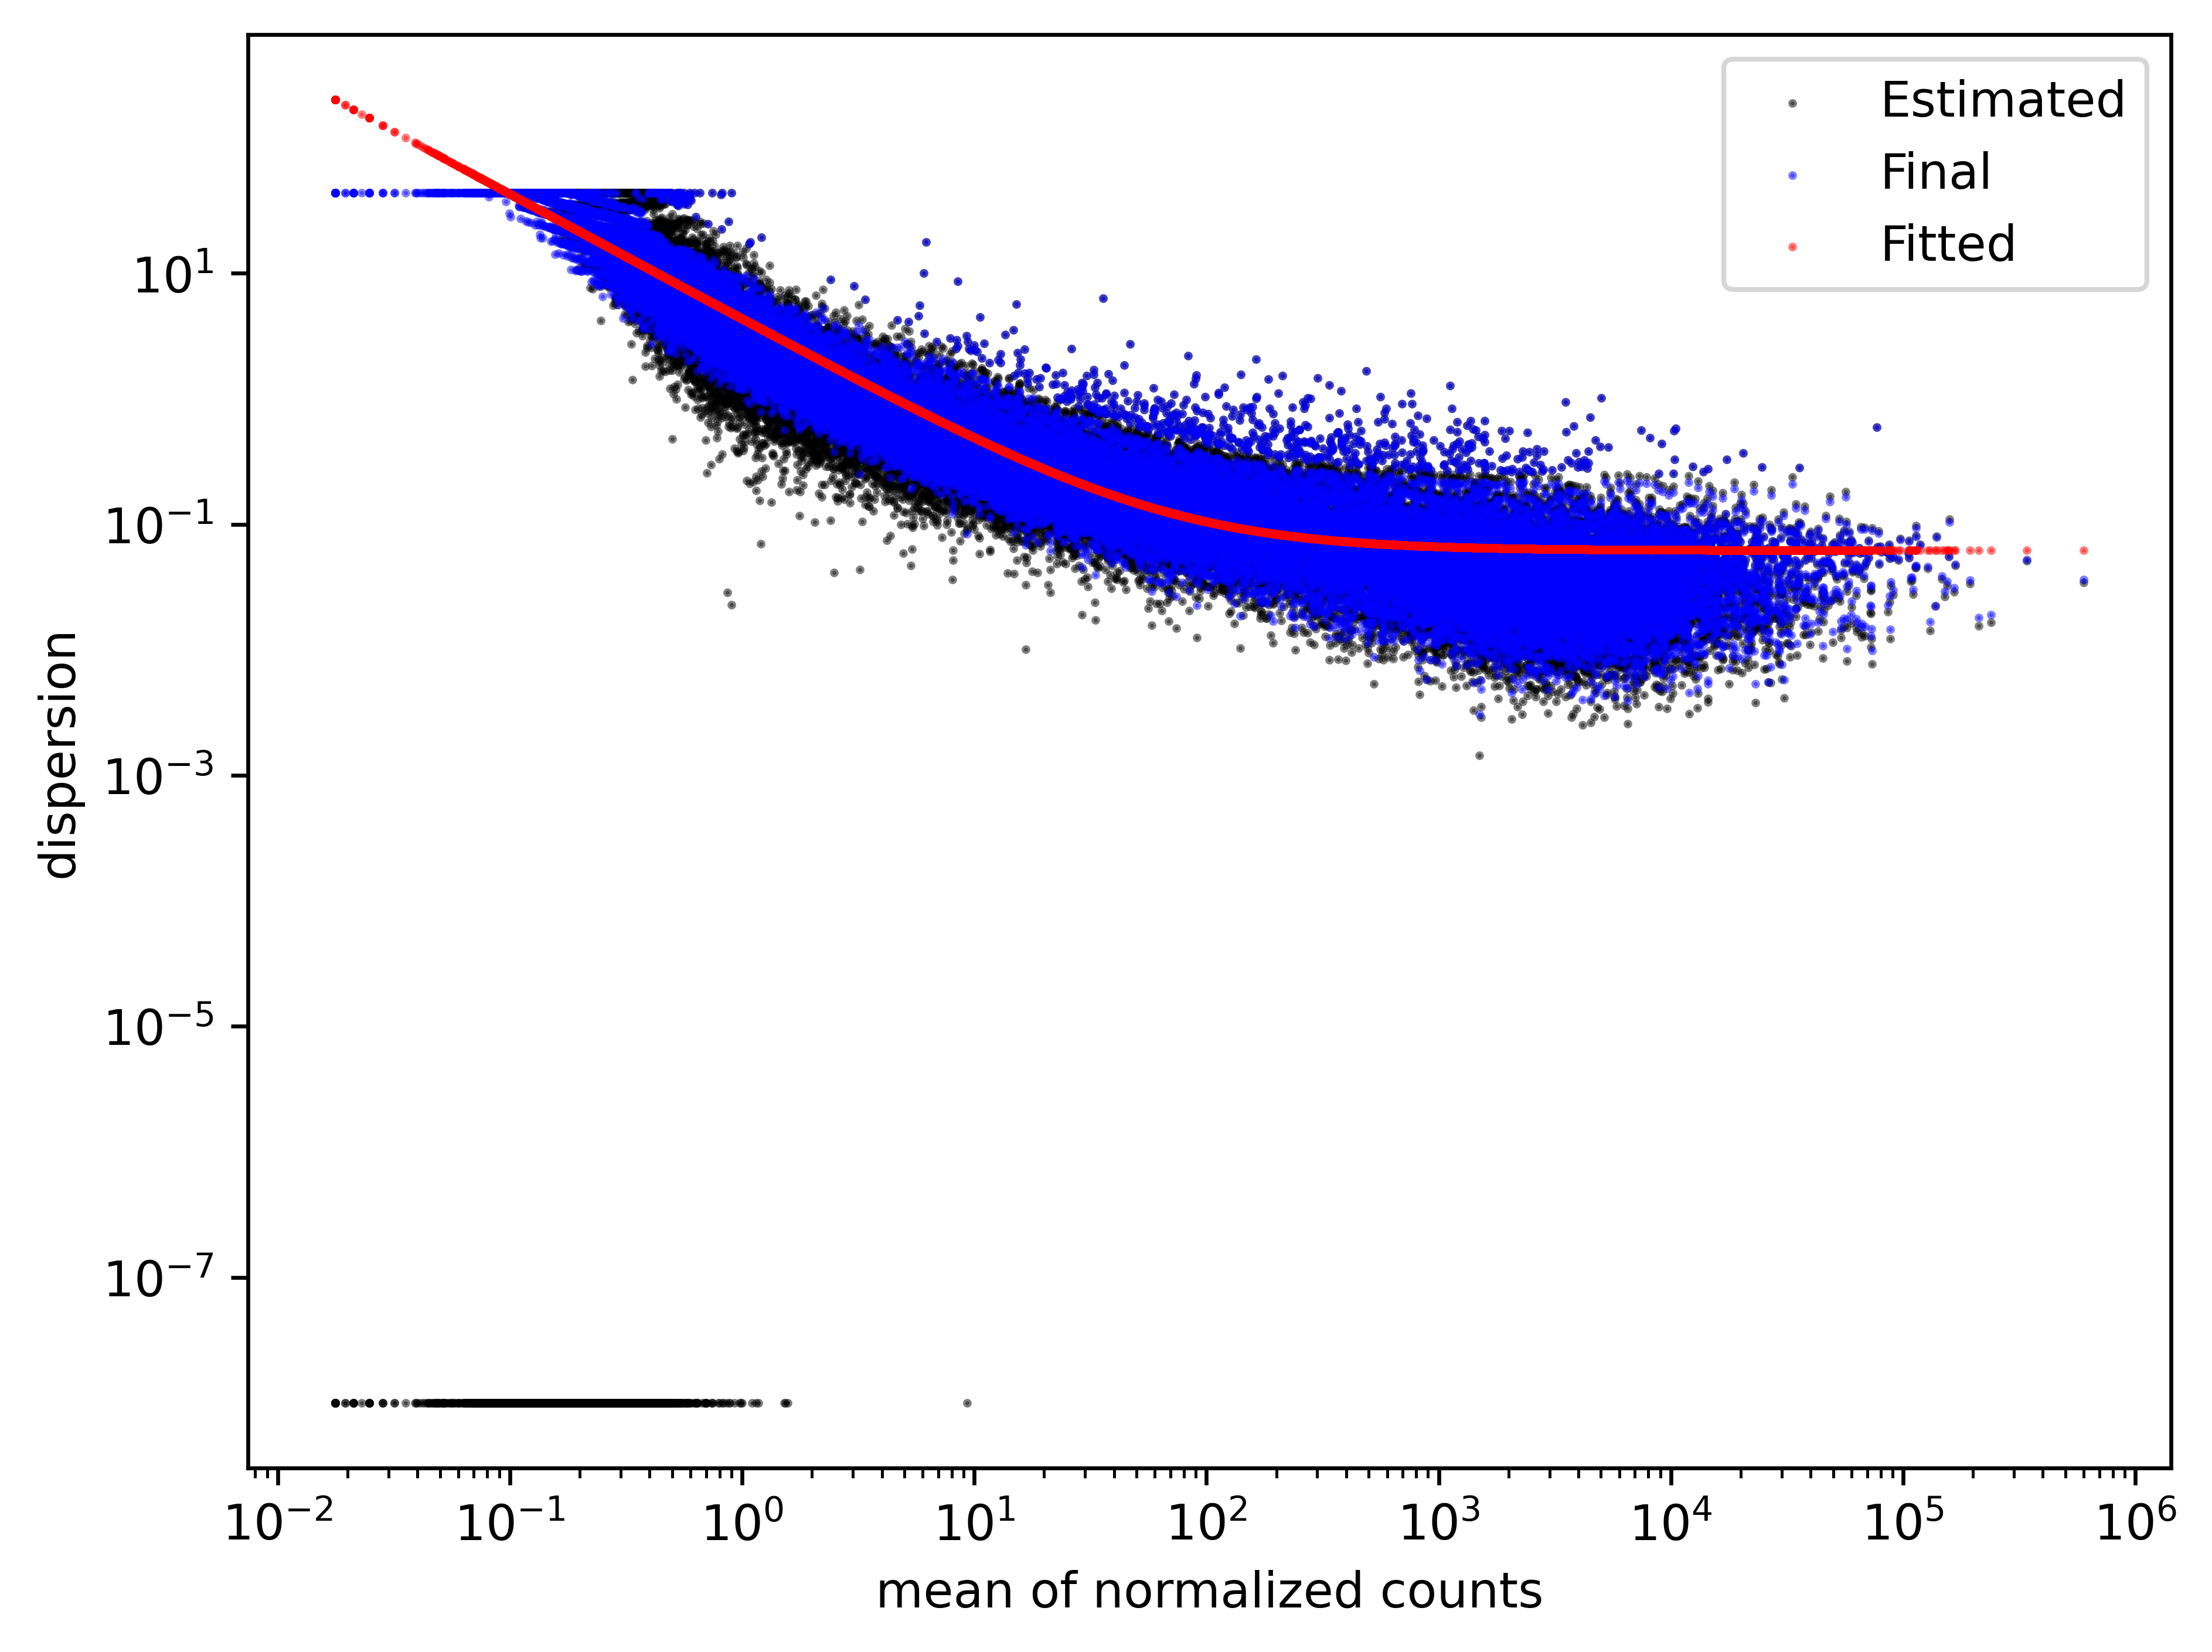

In [ ]:
dds.plot_dispersions(save_path="Dispersion_plot")

## Heatmap

Prend les 10 genes les plus significatifs et ceux aussi d'une liste prédéfinie

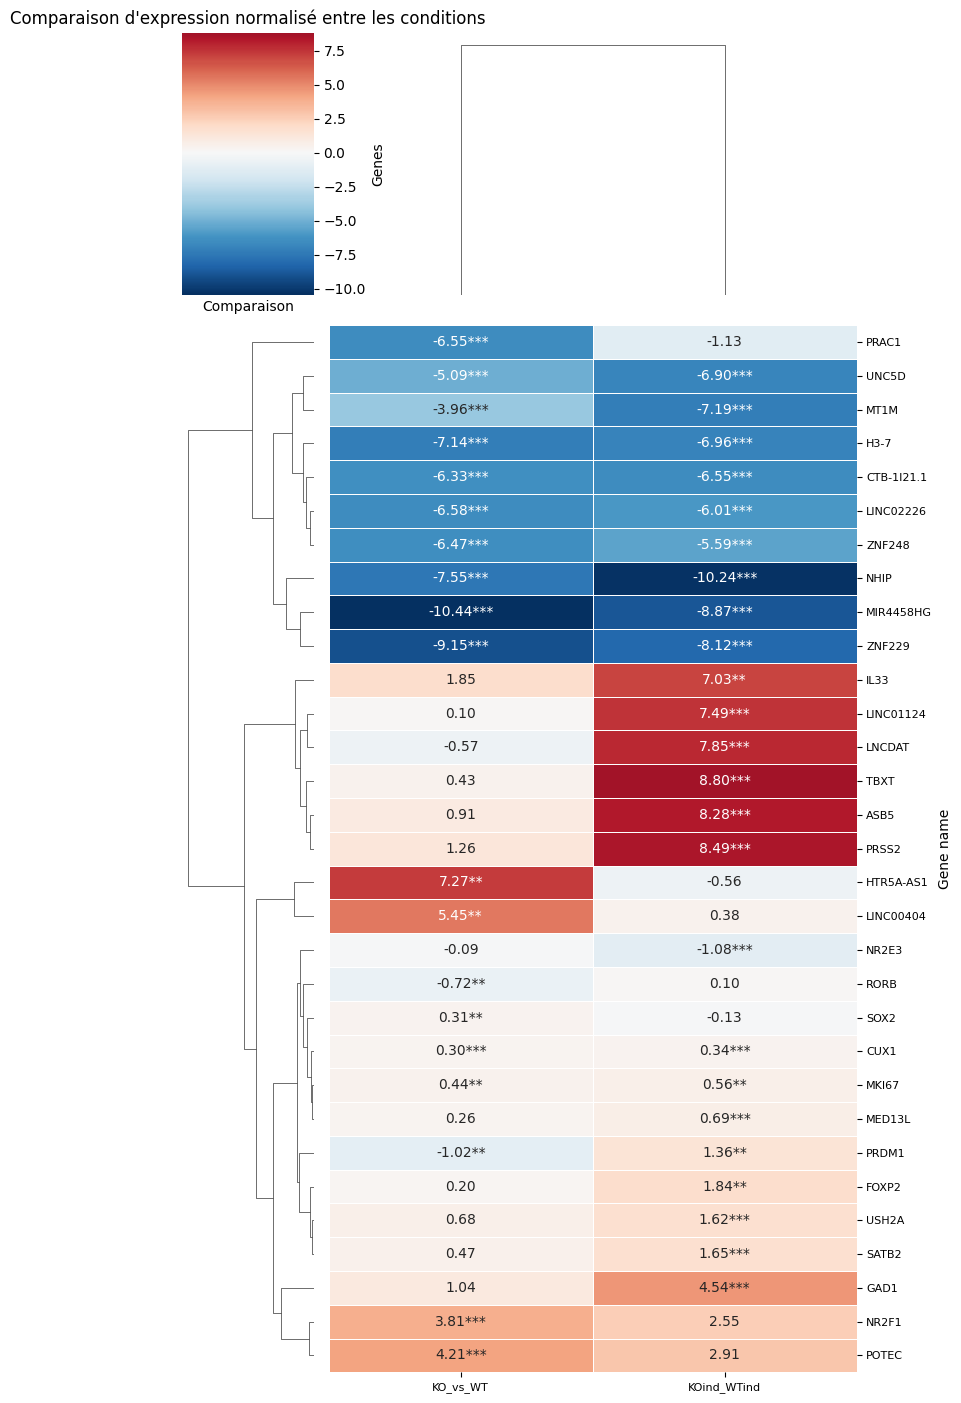

In [64]:
selected_genes=['SOX2', "FOXG1", "TBR2", "TBR1", "BCL11B", "SATB2", "CUX1", "MBP", "PRDM1",
               "RAX", "VSX2", "OTX2", "CRX", "NEUROD1", "RCVRN", "RORB", "THRB", "USH2A", "NRL",
               "NR2E3", "NR2F1", "PAX6", "FOXP2", "GAD1", "MKI67", "FABP7", "NES", "MED13L"]

#Construction de la matrice des log2fc

fc = pd.DataFrame({
    "KO_vs_WT": df_KO_WT_results.set_index("Gene name")["log2FoldChange"],
    "KOind_WTind":df_KO_WT_induced_results.set_index("Gene name")["log2FoldChange"]
})

#selection des gènes significatives

sig_KO_WT = df_KO_WT_results[
    (df_KO_WT_results["padj"]<0.05)&(abs(df_KO_WT_results["log2FoldChange"])>1)
].copy()

sig_KO_WT_induced = df_KO_WT_induced_results[
    (df_KO_WT_induced_results["padj"]<0.05)&(abs(df_KO_WT_induced_results["log2FoldChange"])>1)
].copy()

#Top 10 des gènes différentiellement exprimé

top_up_KO_WT=(sig_KO_WT.sort_values("log2FoldChange", ascending=False).head(10)["Gene name"].dropna().tolist())
top_down_KO_WT=(sig_KO_WT.sort_values("log2FoldChange").head(10)["Gene name"].dropna().tolist())
top_up_KO_WT_induced=(sig_KO_WT_induced.sort_values("log2FoldChange", ascending=False).head(10)["Gene name"].dropna().tolist())
top_down_KO_WT_induced=(sig_KO_WT_induced.sort_values("log2FoldChange").head(10)["Gene name"].dropna().tolist())

#Fusion avec les gènes d'interret

selected_sig_KO_WT = df_KO_WT_results[(df_KO_WT_results["Gene name"].isin(selected_genes))&(df_KO_WT_results["padj"]<0.05)]["Gene name"].tolist()
selected_sig_KO_WT_ind = df_KO_WT_induced_results[(df_KO_WT_induced_results["Gene name"].isin(selected_genes))&(df_KO_WT_induced_results["padj"]<0.05)]["Gene name"].tolist()

selected_genes_extend=list(dict.fromkeys(
    selected_sig_KO_WT+ selected_sig_KO_WT_ind+ top_up_KO_WT+ top_up_KO_WT_induced+ top_down_KO_WT+ top_down_KO_WT_induced
))

#Creation de la heatmap

heatmap_data=fc.loc[fc.index.intersection(selected_genes_extend)]

padj_data=pd.DataFrame({
    "KO_vs_WT": df_KO_WT_results.set_index("Gene name")["padj"],
    "KOind_WTind":df_KO_WT_induced_results.set_index("Gene name")["padj"]
})

padj_heatmap=padj_data.loc[padj_data.index.intersection(selected_genes_extend)]

annotations = heatmap_data.copy().astype(str)

for gene in heatmap_data.index:
    for condition in heatmap_data.columns:
        value = heatmap_data.loc[gene, condition]
        pval=padj_heatmap.loc[gene, condition]
        stars=""
        if pd.notna(pval):
            if pval<0.001:
                stars="***"
            elif pval<0.01:
                stars="**"
            elif pval<0.05:
                stars="**"
        annotations.loc[gene, condition] = f"{value:.2f}{stars}"

g = sns.clustermap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    annot=annotations,
    fmt="",
    linewidth=0.5,
    figsize=(8,14),
    yticklabels=True,
    xticklabels=True
)

g.ax_heatmap.set_yticklabels(
    g.ax_heatmap.get_yticklabels(),
    rotation=0,
    fontsize=8
)

g.ax_heatmap.set_xticklabels(
    g.ax_heatmap.get_xticklabels(),
    rotation=0,
    fontsize=8
)

plt.title("Comparaison d'expression normalisé entre les conditions")
plt.xlabel("Comparaison")
plt.ylabel("Genes")
plt.savefig("Heatmap_comparaison_expression.pdf", format="pdf")
plt.tight_layout()
plt.show()